# Quickstart — Local Content-Style Control

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DigitalMasterpieces/local-content-style/blob/main/examples/quickstart.ipynb)

Two maps steer an SDXL stylization locally: the **content** map *s(p)* (ControlNet Tile strength) and the **style** map *λ(p)* (IP-Adapter scale, per attention block). This notebook runs the settings of two figures of the paper with the public API (`noise="numpy"` reproduces the figures' compositions), lets you adjust them, and launches the interactive demo. The inputs are bundled in `paper/Inputs`.

**On Google Colab:** choose *Runtime → Change runtime type → T4 GPU*, then run the cells in order. The first run downloads the model weights (about 10–15 GB).

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:  # fetch the repository (inputs, demo) and install the package with the demo extras
    if not os.path.exists('local-content-style'):
        !git clone -q https://github.com/DigitalMasterpieces/local-content-style
    %pip install -q './local-content-style[demo]'
    # Colab's preinstalled torchao is older than diffusers expects (and unused here)
    %pip uninstall -y -q torchao
    os.chdir('local-content-style/examples')

In [2]:
from pathlib import Path
import psutil, torch
from PIL import Image
from lcsc import LocalContentStyle, Region

inputs = Path('../paper/Inputs')
gpu = torch.cuda.get_device_properties(0) if torch.cuda.is_available() else None
print('GPU:', f'{gpu.name}, {gpu.total_memory / 1e9:.1f} GB' if gpu else 'none (MPS or CPU)',
      '| RAM: %.1f GB' % (psutil.virtual_memory().total / 1e9))
offload = gpu is not None and gpu.total_memory < 20e9  # e.g. Colab's T4 (15 GB): keep each model on the GPU only while it runs
lcs = LocalContentStyle.load(offload=offload)  # CUDA, then MPS, then CPU; fp16

## Subject vs. background (Fig. 1, *CS*)

The mask marks the background white, so `inside` is the background and `outside` is the subject: the subject keeps more of the photo (higher *s*, lower *λ*), the background is stylized freely.

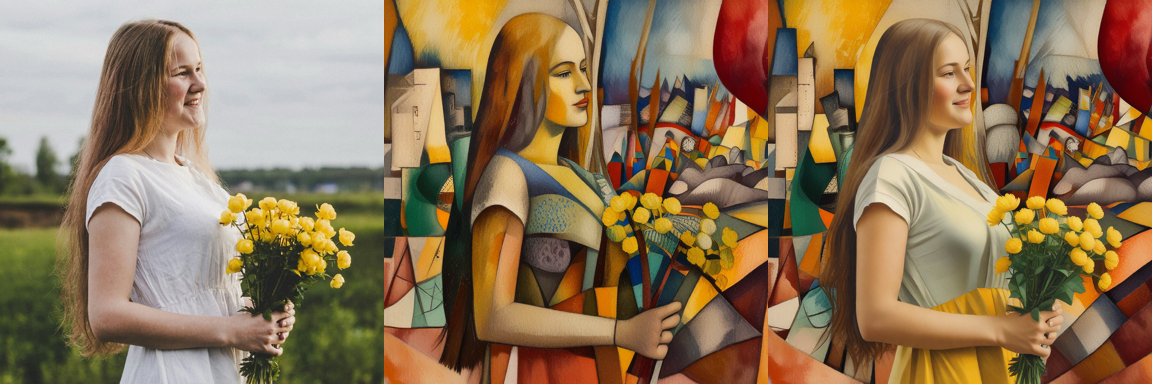

In [3]:
mask = inputs / 'masks/showcase/danila-perevoshchikov-77p2DAx00EA-unsplash-mask.jpeg'
prompt = 'a young woman holding a bouquet of yellow flowers, cubist painting, fragmented forms, Albert Gleizes inspired'
content, style = inputs / 'content/showcase/danila-1024.jpg', inputs / 'styles/gleizes_paysage_cubiste_sq.png'

uniform = lcs(prompt, content, style, content_strength=0.35, style_strength=1.0, seed=1447777030, noise='numpy')
local = lcs(prompt, content, style,
            content_strength=Region(mask, inside=0.35, outside=0.7),
            style_strength=Region(mask, inside=1.0, outside=0.3),
            seed=1447777030, noise='numpy')

def row(*images, size=384):
    out = Image.new('RGB', (size * len(images), size))
    for i, im in enumerate(images):
        out.paste((Image.open(im) if isinstance(im, Path) else im).convert('RGB').resize((size, size)), (i * size, 0))
    return out

row(content, uniform, local)

## Adjust it

Set content and style strength separately for the subject and the background, then run the cell (on Colab, the sliders re-run it). Higher content keeps more of the photo's structure; higher style takes on more of the exemplar.

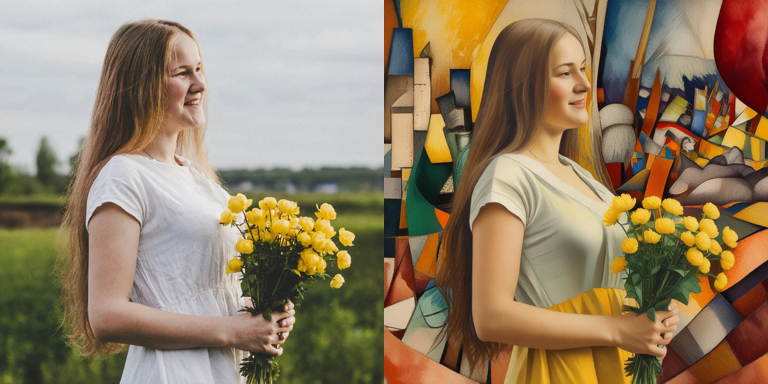

In [4]:
subject_content = 0.7  #@param {type:"slider", min:0, max:1.5, step:0.05}
subject_style = 0.3  #@param {type:"slider", min:0, max:1.5, step:0.05}
background_content = 0.35  #@param {type:"slider", min:0, max:1.5, step:0.05}
background_style = 1.0  #@param {type:"slider", min:0, max:1.5, step:0.05}
seed = 1447777030  #@param {type:"integer"}

# The mask is white on the background, so `inside` is the background and `outside` the subject.
custom = lcs(prompt, content, style,
             content_strength=Region(mask, inside=background_content, outside=subject_content),
             style_strength=Region(mask, inside=background_style, outside=subject_style),
             seed=seed, noise='numpy')
row(content, custom)

## A depth map on one block (Fig. 4, left)

Only InstantStyle's style block (6) is active, and its scale follows the depth map: the exemplar fades out up close.

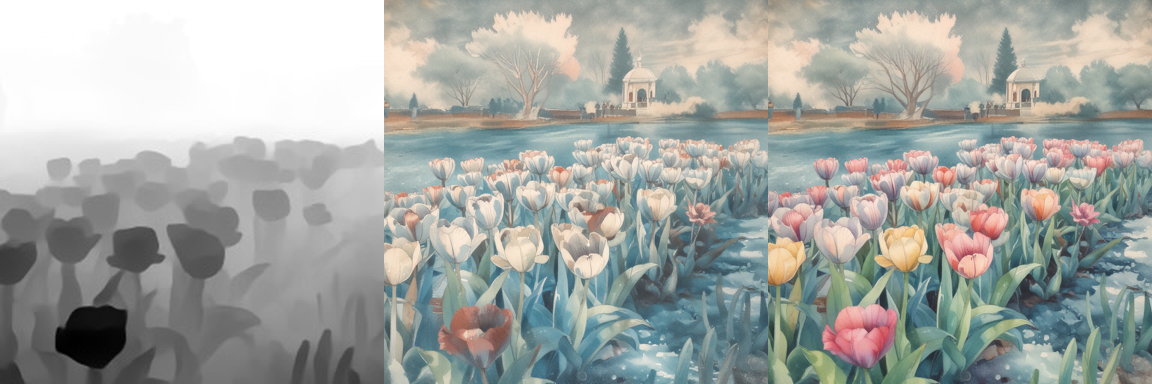

In [5]:
depth = inputs / 'masks/showcase/depth.jpeg'
args = dict(prompt='watercolor style', content_image=inputs / 'content/showcase/depth.jpg',
            style_image=inputs / 'styles/homer_sloop_nassau.png', blocks='style', seed=590662726, noise='numpy')

row(depth, lcs(**args), lcs(**args, block_strength={6: depth}))

## Interactive demo

Brush your own regions on your own images. On Colab this opens the Gradio demo with a public link (stop the cell to end it); locally, run `python demo/app.py` instead.

In [6]:
if IN_COLAB:
    sys.path.insert(0, '../demo')
    import app
    app._lcs = lcs  # reuse the loaded models
    app.build().queue().launch(share=True, debug=True)
else:
    print('Run `python demo/app.py` from the repository root.')